In [1]:
import pandas as pd
import os
from fastai.tabular.all import *

In [2]:
Image_path = '../images_assorted'

if os.path.exists(Image_path):
    print("The file exists.")
else:
    %run ../GenerateVolumes.ipynb

The file exists.


In [3]:
df_path = '../image_data_assorted.csv'
df = pd.read_csv(df_path)

In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,53,254,209,1404,181,148877,images_assorted/image_1.png,masks_assorted/mask_1.png,triange
1,19,158,255,1134,60,28716,images_assorted/image_2.png,masks_assorted/mask_2.png,circle
2,84,421,391,7056,336,592704,images_assorted/image_3.png,masks_assorted/mask_3.png,square
3,75,101,86,17662,236,1766250,images_assorted/image_4.png,masks_assorted/mask_4.png,circle
4,113,429,331,6384,386,1442897,images_assorted/image_5.png,masks_assorted/mask_5.png,triange


In [5]:
def get_inputs(row):
    # Convert image path to PILImage
    data1 = row['Radius']
    data2 = row['X_Position']
    data3 = row['Y_Position']    
    data4 = row['Area'] 
    data5 = row['Surface2d'] 
    data6 = row['Volume'] 

    dataset = [data1, data2, data3, data4, data5, data6]
    dataset = torch.tensor(dataset, dtype=torch.float32)  # Explicitly cast to float
    return dataset

def get_target(row):
    # Convert image path to PILImage
    target_data = row['shape']
    return target_data

In [6]:
dblock = DataBlock(
    blocks=(RegressionBlock, CategoryBlock),  # Image input and auxiliary input
    get_x=get_inputs,  # Get both the image path and the auxiliary input
    get_y=get_target  # Get the radius value from the dataframe
    #splitter=RandomSplitter(valid_pct=0.2, seed=42),  # Split into train and validation sets
)
dls = dblock.dataloaders(df, bs=512)

In [7]:
print(dls.vocab)

['circle', 'square', 'triange']


In [8]:

# Assuming your SimpleFeedForwardNN model is defined as shown before
class Simplemodel(nn.Module):
    def __init__(self ):
        super(Simplemodel, self).__init__()
        
        #self.conv_fc = nn.Conv2d(in_channels=1, out_channels=new_channels, kernel_size=1)
        self.fc1 = nn.Linear(6, 64)
        self.fc2 = nn.Linear(64, 256)
        self.fc3 = nn.Linear(256, 512)
        self.fc4 = nn.Linear(512, 512)
        self.fc5 = nn.Linear(512, 128)
        self.fc6 = nn.Linear(128, 32)
        self.finalshape = nn.Linear(32, 3) # 1 out for each feature 
        #self.final_weight_multi = nn.Parameter(torch.tensor(5.0))  
        #self.final_weight_add = nn.Parameter(torch.tensor(5.0))          
        
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        #print(x.shape)
        # step 2 feed 
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        #x = self.sigmoid(x)
        x = self.relu(self.fc4(x))
        x = self.relu(self.fc5(x))
        x = self.relu(self.fc6(x))
        x = self.finalshape(x)      
                
        #print(x.shape)
        return x


In [9]:
###########################################################
# Create model and learner
###########################################################

model = Simplemodel()

learn = Learner(
    dls,
    model,
    metrics=accuracy,
    loss_func=CrossEntropyLossFlat()
)

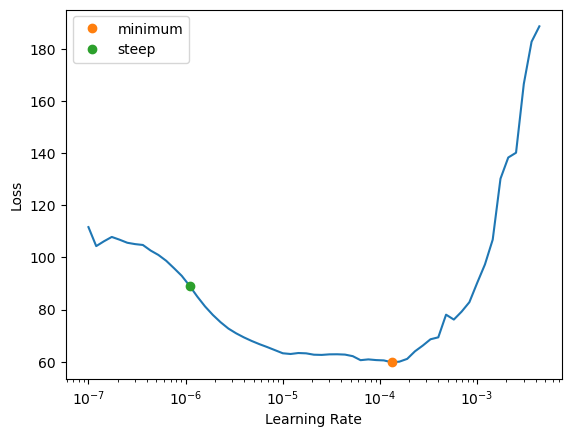

In [10]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

In [11]:
learn.fit_one_cycle(100,lr_max=lr_steep)


epoch,train_loss,valid_loss,accuracy,time
0,109.249260,122.874123,0.320000,00:00
1,109.706314,122.180443,0.320000,00:00
2,107.107529,121.321541,0.320000,00:00
3,105.919434,120.198242,0.320000,00:00
4,107.200638,118.729362,0.320000,00:00
5,106.032486,116.834229,0.320000,00:00
6,106.631493,114.437248,0.320000,00:00
7,106.473053,111.498955,0.325000,00:00
8,104.966080,107.998611,0.325000,00:00
9,104.283875,103.853935,0.325000,00:00


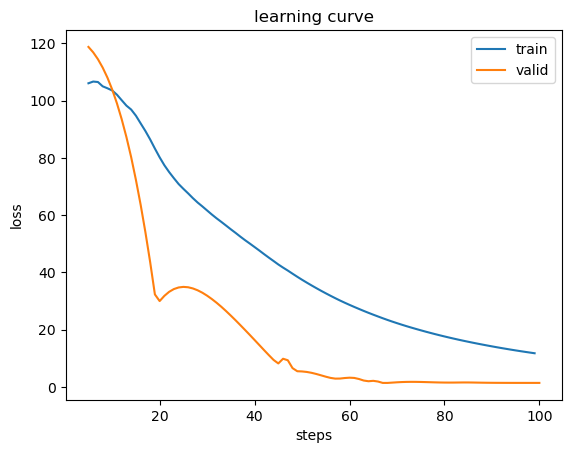

In [12]:
###########################################################
# Plot training and validation losses
###########################################################

learn.recorder.plot_loss()

# Optional y-axis limits
# plt.ylim(0, 5)

plt.show()

In [13]:
print("Vocabulary:", learn.dls.vocab)

Vocabulary: ['circle', 'square', 'triange']


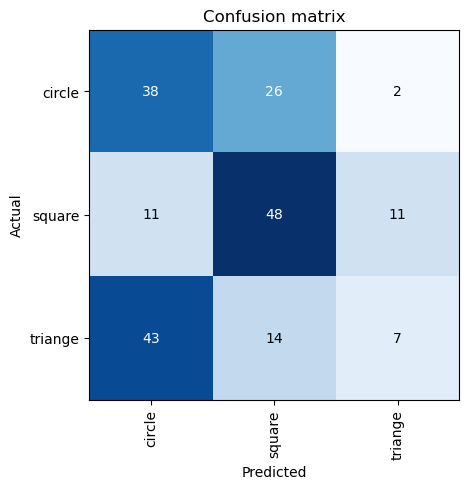

In [14]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

In [15]:


learn.export('exported_classification_tabular_model.pkl')
 


In [16]:
# import

learn2 = load_learner('exported_classification_tabular_model.pkl')   # using learner2 to show its loading

C:\Users\bowan\anaconda3\Lib\site-packages\fastai\learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [22]:
###########################################################
# Select row to predict
###########################################################

n = 1  # indexing starts at 0

nth_row = df.iloc[n]

###########################################################
# Make prediction
###########################################################

Prediction, ClassID, Confidence = learn2.predict(nth_row)



In [23]:
###########################################################
# Display prediction
###########################################################
print("Prediction:", Prediction)
print("Class ID:", ClassID)
print("Confidence:", Confidence)

Prediction: square
Class ID: tensor(1)
Confidence: tensor([0.0507, 0.9033, 0.0460])
